# Multiview CCA analysis of cross-condition connectome translation

**Spec v4 E5** (`context_packages/repo_spec_docs/spec_doc_v4.md`, slug `cca_analysis`) · Glasser 360 parcellation ·
matched cohort of 917 HCP subjects · seeds 0–4 · last executed by `scripts/experiments/cca_analysis` results.

**Abstract.** We asked whether a multiview CCA co-embedding of nine views (SC, rest FC, seven task FCs) is a better space in which to translate one view into another than four PCA representations, evaluated on 917 HCP subjects over five seeds. Full-rank CCA with ridge decoders beats the best PCA representation (variance-adjusted block PCA) on identification across the 72 view pairs (average rank +0.027, 5 / 5 seeds) without losing accuracy, with the largest gain for FC → SC; it gives nothing for SC → FC. Pooling the CCA encodings of the other views beats any single source and concatenated PCA codes (H2). A composite loss on the CCA decoders trades accuracy for identification: demeaned corr-eye raises average rank by +0.04 at a cost of 0.011 demeaned r, while neighbour distance gives +0.010 at a cost of 0.003 (H3). Copying a subject's own residual from another condition still identifies them better than any learned map.

**Contents**
1. [Problem](#1-problem): data view and descriptive statistics of subject-specific residuals
2. [Approach](#2-approach): latent representations (R0–R3, multiview CCA) and the transfer methods
3. [H1 — CCA gain over PCA representations, every view pair](#3-h1)
4. [H2 — consensus of the other views → held-out view](#4-h2)
5. [H3 — composite loss on the CCA decoders](#5-h3)
6. [Conclusions](#6-conclusions)
7. [Appendix: gates and reproducibility](#7-appendix)

**This notebook is a renderer.** Every number is computed by SLURM jobs in `scripts/experiments/cca_analysis/`
(`run_seed.py`: representations, H1, H2; `run_composite.py`: H3; `run_descriptives.py`: section 1; `analyze.py`:
contrasts and tables). The notebook only loads their outputs (`results/cache/experiments/cca_analysis/` and the
experiment's `tables/`), applies the fixed selection rules stated in the text, and draws the figures. Re-render with
`sbatch scripts/experiments/cca_analysis/launch/render_notebook.sh`. Statistics are paired by seed: each contrast is averaged over the cells in scope within a seed, then
summarised as mean ± SE over the five seeds with the number of seeds in favour.

In [1]:
import sys, json
from pathlib import Path

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "main.py").exists())
EXP = REPO_ROOT / "scripts" / "experiments" / "cca_analysis"
sys.path[:0] = [str(REPO_ROOT), str(EXP)]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

import analyze as A
from e5_common import CFG, FC, VIEWS, to_matrix, N_NODES

pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)
RC = A.fig_rc()
plt.rcParams.update(RC)

df, G0, SEL = A.load_e51()
DV = np.load(A.OUT / "render" / "data_view_seed0.npz")          # data-view arrays (run_descriptives.py)
DESC = pd.read_csv(EXP / "tables" / "descriptives_pairs.csv")   # residual similarity per seed (run_descriptives.py)
H3, G1, CURVES, SCALES = A.load_h3()
print(f"E5.1 rows: {len(df):,} from seeds {sorted(G0)}; H3 rows: {len(H3):,} from seeds {sorted(G1)}")
print("G0 (E5.1 gate) per seed:", {s: g["pass"] for s, g in G0.items()})
print("G1 (H3 gate) per seed:  ", {s: g["pass"] for s, g in G1.items()})

E5.1 rows: 5,275 from seeds [0, 1, 2, 3, 4]; H3 rows: 4,770 from seeds [0, 1, 2, 3, 4]
G0 (E5.1 gate) per seed: {0: True, 1: True, 2: True, 3: True, 4: True}
G1 (H3 gate) per seed:   {0: True, 1: True, 2: True, 3: True, 4: True}


<a id="1-problem"></a>
## 1. Problem

Let $i = 1, \dots, n$ index subjects and $m \in \mathcal{M} = \{\mathrm{SC}, \mathrm{rest}, \mathrm{emotion},
\mathrm{gambling}, \mathrm{language}, \mathrm{motor}, \mathrm{relational}, \mathrm{social}, \mathrm{wm}\}$ the nine
**views** (structural connectivity and functional connectivity in rest and seven tasks). Each connectome is a symmetric
$360 \times 360$ matrix $X_i^m$, vectorised as its upper triangle $x_i^m \in \mathbb{R}^{E}$, $E = 64{,}620$.

With $\bar x^m = \frac{1}{n_{\mathrm{train}}} \sum_{i \in \mathrm{train}} x_i^m$ the train mean of view $m$, the
quantity of interest is the **subject-specific, condition-specific residual**

$$ r_i^m = x_i^m - \bar x^m . $$

The group mean $\bar x^m$ explains most of the variance of every connectome (raw Pearson r of a subject with the mean is
≈ 0.8 for FC), so a model that predicts $\bar x^m$ already looks accurate; everything individual lives in $r_i^m$. The
task is to learn, for every ordered pair of views $a \to b$, a map $f_{a \to b}$ such that
$\hat x_i^b = \bar x^b + f_{a \to b}(x_i^a)$ recovers $r_i^b$ for **held-out** subjects (splits 659 / 74 / 184 at seed 0).

**Evaluation** (test subjects, $n_{\mathrm{test}} \approx 184$). With $C_{ij} = \mathrm{corr}(x_i^b, \hat x_j^b)$
(Pearson over edges) and $\tilde C_{ij} = \mathrm{corr}(r_i^b, \hat x_j^b - \bar x^b)$:
- **demeaned r** $= \frac{1}{n} \sum_i \tilde C_{ii}$: accuracy of the predicted residual;
- **average rank** $= \frac{1}{n} \sum_i \big(1 - \mathrm{rank}_i / n\big)$, where $\mathrm{rank}_i$ is the
  0-based position of subject $i$'s own prediction when row $i$ of $C$ is sorted in decreasing order: identification
  (1 = always first, 0.5 = chance);
- **top-1** $= \frac{1}{n} \sum_i \mathbb{1}[\arg\max_j C_{ij} = i]$.

Model selection uses the validation **average rank** (spec v4 D9); test values are reported.

### 1.1 Data view: one subject across the nine views

Rows: the raw connectomes $X_i^m$ and the residuals $X_i^m - \bar X^m$ of one test subject (seed 0 split).
Nodes are ordered by Yeo-7 community (Glasser parcels' assignment), then hemisphere; lines mark community boundaries.
Colour limits are per view (99th percentile of $|\cdot|$).

findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Fon

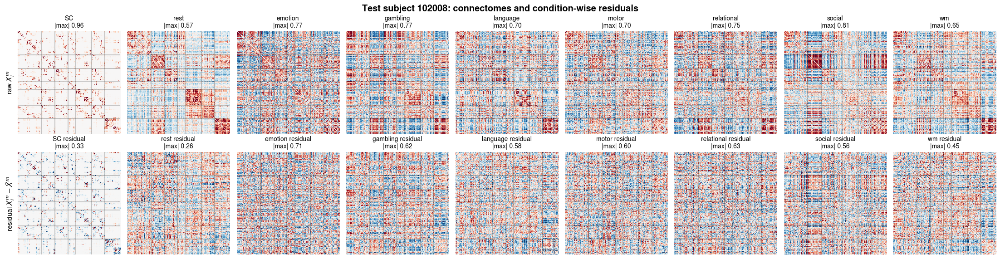

In [2]:
atlas = pd.read_csv(REPO_ROOT / "data" / "atlas_info" / "Glasser_dseg_reformatted.csv")
comm = atlas["community_yeo"].astype(str).to_numpy()
order = np.lexsort((atlas["hemisphere"].astype(str).to_numpy(), comm))
bounds = np.flatnonzero(comm[order][1:] != comm[order][:-1]) + 0.5

SUBJ = 0                                             # first test subject of seed 0
raw = {v: to_matrix(DV[f"edges__{v}"][SUBJ][None].astype(np.float64))[0] for v in VIEWS}
dev = {v: raw[v] - to_matrix(DV[f"train_mean__{v}"][None].astype(np.float64))[0] for v in VIEWS}

def show_row(axes, mats, cmap, title_fmt):
    for ax, v in zip(axes, VIEWS):
        M = mats[v][np.ix_(order, order)]
        lim = np.percentile(np.abs(M[np.triu_indices(N_NODES, 1)]), 99)
        lo = 0 if (cmap == "viridis") else -lim
        ax.imshow(M, cmap=cmap, vmin=lo, vmax=lim, interpolation="nearest")
        for b in bounds:
            ax.axhline(b, color="k", lw=0.3); ax.axvline(b, color="k", lw=0.3)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(title_fmt.format(v=v, lim=lim), fontsize=10)
        for s in ax.spines.values():
            s.set_visible(False)

fig, axes = plt.subplots(2, 9, figsize=(22, 5.6), layout="constrained")
show_row(axes[0], raw, "RdBu_r", "{v}\n|max| {lim:.2f}")
show_row(axes[1], dev, "RdBu_r", "{v} residual\n|max| {lim:.2f}")
axes[0, 0].set_ylabel("raw $X_i^m$", fontsize=11)
axes[1, 0].set_ylabel(r"residual $X_i^m - \bar X^m$", fontsize=11)
fig.suptitle(f"Test subject {int(DV['subject_ids'][SUBJ])}: connectomes and condition-wise residuals",
             fontweight="bold")
plt.show()

The raw FC matrices of the eight conditions look alike: the shared network architecture dominates. Their residuals do
not: each condition's residual has its own pattern, and the SC residual has a different structure altogether (sparse,
with large values on strong tracts). Section 1.2 quantifies how much of a residual is shared across views.

### 1.2 Descriptive statistics: how much of a subject's residual is shared across views

For views $a, b$ and test subjects $i, j$: $S^{ab}_{ij} = \mathrm{corr}(r_i^a, r_j^b)$. The diagonal mean is the
**within-subject residual similarity** (the demeaned r obtained by copying the source residual, the "copy" baseline of
H1); the average rank and top-1 of $S^{ab}$ (rows $= b$) measure whether a subject's residual in $a$ identifies their
residual in $b$. Same quantities as the deviation-similarity analysis
(`scripts/notebooks/EDA/figures/fc_conditions/deviation_similarity/`, interactive:
[`deviation_similarity_viewer`](../../data_viewers/deviation_similarity_viewer/deviation_similarity_viewer.html)), here on
each seed's test split (≈ 184 subjects; mean over the 5 seeds) and including SC. Computed by
`scripts/experiments/cca_analysis/run_descriptives.py`.

findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Fon

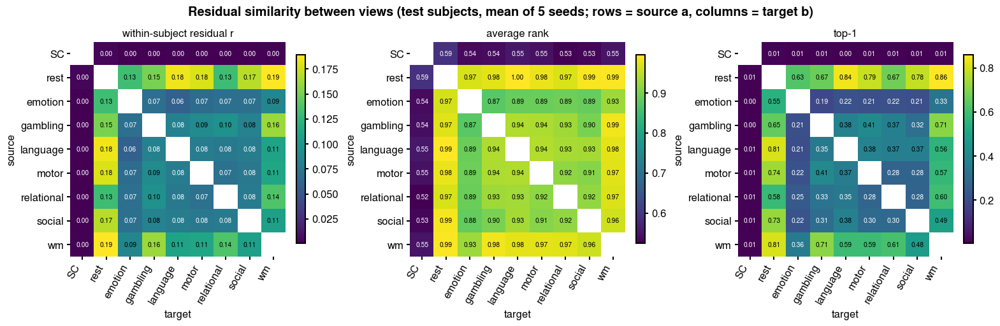

,within-subject residual r,average rank,top-1
FC ↔ FC (56 pairs),0.1071,0.9409,0.4583
SC → FC,0.0013,0.5477,0.0078
FC → SC,0.0013,0.5472,0.0067


In [3]:
mean_desc = DESC.groupby(["source", "target"])[["within_r", "avg_rank", "top1_acc"]].mean()
stats = {lab: mean_desc[k].unstack().reindex(index=VIEWS, columns=VIEWS)
         for k, lab in (("within_r", "within-subject residual r"), ("avg_rank", "average rank"), ("top1_acc", "top-1"))}
A.heatmaps(list(stats.values()), list(stats.keys()),
           "Residual similarity between views (test subjects, mean of 5 seeds; rows = source a, columns = target b)", fmt_="{:.2f}")
plt.show()
off = lambda M: M.values[~np.isnan(M.values)]
fcfc = lambda M: M.loc[FC, FC].values[~np.isnan(M.loc[FC, FC].values)]
display(pd.DataFrame({k: [fcfc(M).mean(), M.loc["SC", FC].mean(), M.loc[FC, "SC"].mean()] for k, M in stats.items()},
                     index=["FC ↔ FC (56 pairs)", "SC → FC", "FC → SC"]))

**Copy (identity pass-through) as a predictor.** The same pairs scored as a model: the prediction for view $b$ is
$\hat x_i^b = \bar x^b + r_i^a$ (target train mean plus the source residual, no fitting), evaluated like every model in
sections 3–5. Demeaned r equals the within-subject residual r above; average rank and top-1 are computed on the full
predicted connectome against the full true connectome (the convention for every model), so the shared group mean
lowers them relative to the residual-only identification above. **SC row and column (dashed) are a null:** SC and FC
residuals are different quantities on the same edge index and share nothing edge-wise, so copying across them shows
what chance looks like under this scoring (average rank 0.5 = chance). Computed by
`scripts/experiments/cca_analysis/run_descriptives.py` (`tables/copy_pairs.csv`; FC → FC equals `run_seed.py`'s H1
`copy` rows), mean of 5 seeds.

findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Fon

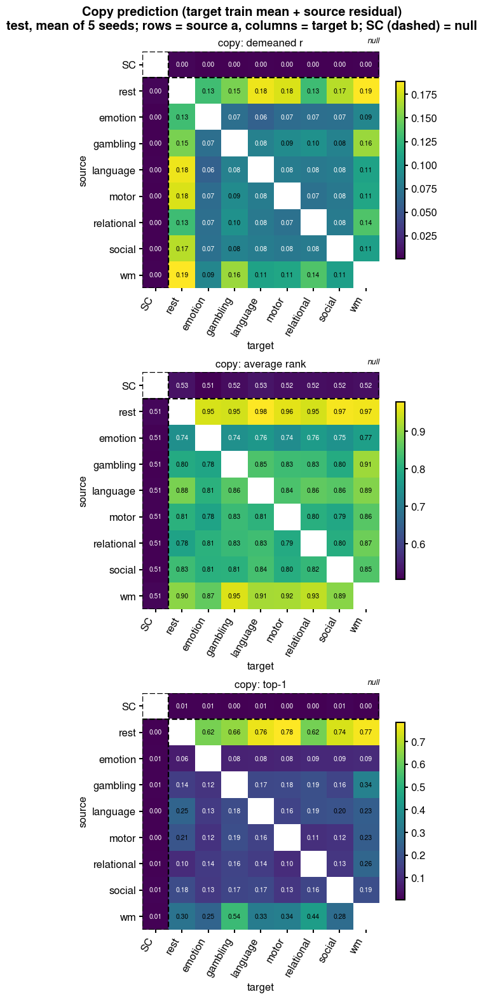

,demeaned r,average rank,top-1
"copy, FC → FC (56 pairs)",0.1071,0.8445,0.2493
null: copy SC → FC (8),0.0013,0.5224,0.0055
null: copy FC → SC (8),0.0013,0.5083,0.0051


max |copy table - H1 copy rows| (FC → FC average rank): 2.220446049250313e-16


In [4]:
from matplotlib.patches import Rectangle
COPY = pd.read_csv(EXP / "tables" / "copy_pairs.csv")
mean_copy = COPY.groupby(["source", "target"])[list(A.METRICS)].mean()
copy_stats = {lab: mean_copy[k].unstack().reindex(index=VIEWS, columns=VIEWS) for k, lab in A.METRICS.items()}
fig = A.heatmaps(list(copy_stats.values()), [f"copy: {lab}" for lab in copy_stats],
                 "Copy prediction (target train mean + source residual)\ntest, mean of 5 seeds; rows = source a, "
                 "columns = target b; SC (dashed) = null", fmt_="{:.2f}", vertical=True)
for ax in fig.axes[:len(copy_stats)]:                       # the heatmaps (subplots come first, colourbars after)
    n = len(VIEWS)
    for xy, w, h in (((-0.5, -0.5), n, 1), ((-0.5, -0.5), 1, n)):   # SC row, SC column
        ax.add_patch(Rectangle(xy, w, h, fill=False, ls="--", lw=1.6, ec="black"))
    ax.text(n - 0.5, -0.75, "null", ha="right", va="bottom", fontsize=9, style="italic")
plt.show()
blk = lambda M, r, c: M.loc[r, c].values[~np.isnan(M.loc[r, c].values)].mean()
display(pd.DataFrame({lab: [blk(M, FC, FC), blk(M, ["SC"], FC), blk(M, FC, ["SC"])] for lab, M in copy_stats.items()},
                     index=["copy, FC → FC (56 pairs)", "null: copy SC → FC (8)", "null: copy FC → SC (8)"]))
check = df[(df.hyp == "H1") & (df.model == "copy")].groupby(["source", "target"]).avg_rank.mean()
print("max |copy table - H1 copy rows| (FC → FC average rank):",
      float((mean_copy.avg_rank.reindex(check.index) - check).abs().max()))

**Copy in the shared block-PCA codes.** The same pass-through, restricted to the shared, variance-adjusted block-PCA
basis (spec v4 D2): the source is encoded, $z = W_{:k}^\top (x_i^a - \bar x^a)/s_a$, and decoded as the target,
$\hat x_i^b = \bar x^b + s_b W_{:k} z$ (no fitting; spec v4 E4.0's "B0-codes"). At $k = 256$ (the code size of E1 / E4);
the table puts it next to the edge-space copy: how much of copy's accuracy and identification survives truncation to the
shared basis. SC (dashed) has its own basis, so its pairs copy coordinates between
unrelated bases: a null. Computed by `scripts/experiments/cca_analysis/run_copy_codes.py`
(`tables/copy_codes_pairs.csv`), mean of 5 seeds.

findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Fon

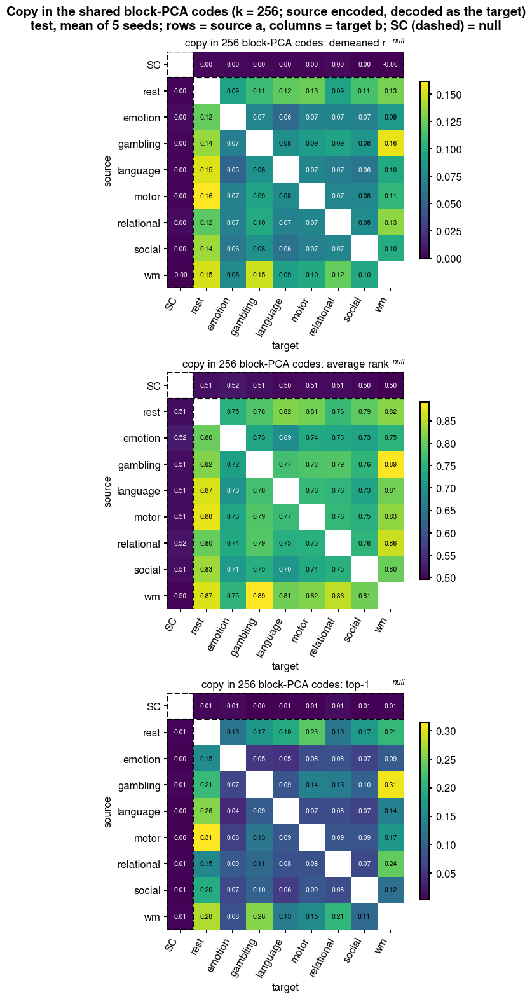

,demeaned r,average rank,top-1
"copy, FC → FC (56 pairs): code size",,,
256,0.0952 ± 0.0008,0.7795 ± 0.0025,0.1301 ± 0.0013
"edges (all 64,620)",0.1071 ± 0.0007,0.8445 ± 0.0027,0.2493 ± 0.0037


In [5]:
COPYK = pd.read_csv(EXP / "tables" / "copy_codes_pairs.csv")
K_SHOW = 256
mean_k = COPYK[COPYK.k == K_SHOW].groupby(["source", "target"])[list(A.METRICS)].mean()
copyk_stats = {lab: mean_k[k].unstack().reindex(index=VIEWS, columns=VIEWS) for k, lab in A.METRICS.items()}
fig = A.heatmaps(list(copyk_stats.values()), [f"copy in {K_SHOW} block-PCA codes: {lab}" for lab in copyk_stats],
                 f"Copy in the shared block-PCA codes (k = {K_SHOW}; source encoded, decoded as the target)\n"
                 "test, mean of 5 seeds; rows = source a, columns = target b; SC (dashed) = null", fmt_="{:.2f}", vertical=True)
for ax in fig.axes[:len(copyk_stats)]:
    n = len(VIEWS)
    for xy, w, h in (((-0.5, -0.5), n, 1), ((-0.5, -0.5), 1, n)):
        ax.add_patch(Rectangle(xy, w, h, fill=False, ls="--", lw=1.6, ec="black"))
    ax.text(n - 0.5, -0.75, "null", ha="right", va="bottom", fontsize=9, style="italic")
plt.show()
fcfc = COPYK[COPYK.source.isin(FC) & COPYK.target.isin(FC)]
tab = A.seed_mean(fcfc, ["k"]).set_index("k")
edge = A.seed_mean(COPY[COPY.source.isin(FC) & COPY.target.isin(FC)].assign(k="edges (all 64,620)"), ["k"]).set_index("k")
tab = pd.concat([tab, edge])
display(tab.assign(**{lab: [A.fmt(m, s) for m, s in zip(tab[f"{k}_mean"], tab[f"{k}_se"])] for k, lab in A.METRICS.items()})
        [list(A.METRICS.values())].rename_axis("copy, FC → FC (56 pairs): code size"))

Reference figure from the deviation-similarity EDA (all seeds' subjects, FC only):

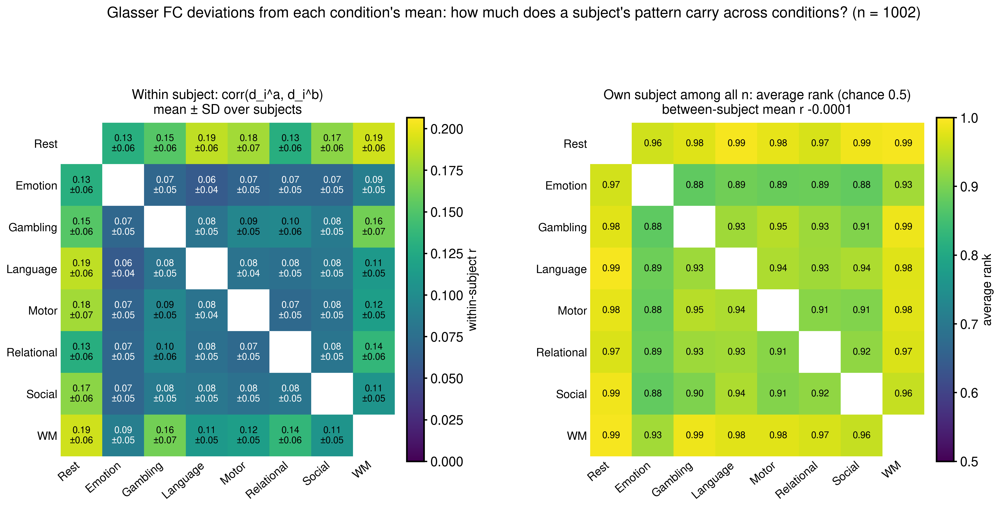

In [6]:
display(Markdown("Reference figure from the deviation-similarity EDA (all seeds' subjects, FC only):"))
display(Image(filename=str(REPO_ROOT / "scripts/notebooks/EDA/figures/fc_conditions/deviation_similarity/deviation_similarity_Glasser.png"), width=1100))

**Reading.** Across the 56 FC ↔ FC pairs, a subject's residual in one condition correlates only weakly with their
residual in another (within-subject residual r 0.107 on average, 0.06–0.19), yet it identifies them well (average rank
0.94, top-1 0.46; rest and working memory are the most mutually identifying, emotion the least). The individual signal
shared across conditions is therefore small in variance but highly specific. SC and FC residuals share essentially
nothing edge-wise (r ≈ 0.001, average rank 0.55, top-1 < 0.01): any SC ↔ FC relation must be learned, not copied.
Copying the source residual is therefore a strong FC → FC baseline for identification, and no baseline at all for
pairs involving SC.

<a id="2-approach"></a>
## 2. Approach: transfer functions between latent representations

Every method has the same form: encode the source connectome into a representation, map it linearly to the target
view, decode to the target's edges:

$$ \hat x_i^b = \bar x^b + \mathrm{dec}_b\big( T_{a \to b}\, \mathrm{enc}_a(x_i^a) \big). $$

The representations differ in what they keep (and therefore what a linear map between them can use); the transfer
$T_{a \to b}$ is fitted by ridge regression or a conditional Gaussian; for CCA the encoder is shared across pairs and
$T$ is a ridge decoder to native edge space.

### 2.1 Latent embedding forms

Notation: $X^m \in \mathbb{R}^{n_{\mathrm{train}} \times E}$ stacks the train subjects of view $m$,
$R^m = X^m - \mathbf{1} (\bar x^m)^\top$ its residuals. SC always keeps its own basis.

**R0 — nodal PCA of the mean train connectome.** Let $\bar X^m \in \mathbb{R}^{360 \times 360}$ be the mean train
matrix of view $m$ (zero diagonal). A PCA of its *rows* (each region's mean connectivity profile) gives
$V^m \in \mathbb{R}^{360 \times q}$, the top-$q$ right singular vectors of the column-centred $\bar X^m$. Each
connectome is encoded row by row through this basis and flattened:

$$ F_i^m = (X_i^m - \bar X^m)\, V^m \in \mathbb{R}^{360 \times q}, \qquad z_i^m = \mathrm{vec}(F_i^m) \in \mathbb{R}^{360 q}. $$

Decoding uses symmetry: with $P = V V^\top$ and $D = X - \bar X$, $F = DV$ determines $DP$, $PD = V F^\top$ and
$PDP = V (V^\top F) V^\top$, so $\hat X = \bar X + F V^\top + V F^\top - V V^\top F V^\top$ (exact when $D$ lies in the
span). *Interpretation:* each region keeps its residual connectivity to $q$ group-level "connectivity gradients"
(axes of the group connectome), so features are anatomically indexed (region × gradient) but the basis is fixed by
the *group mean*, not by how subjects vary. $q \in \{2, 4, 8, 16\}$ (720–5,760 features), chosen on val.

**R1 — condition-specific PCA.** $R^m = U^m \Sigma^m (W^m)^\top$; codes $z_i^m = (W^m_{:k})^\top r_i^m$.
*Interpretation:* the $k$ directions along which subjects vary most *in that view*; code $j$ of rest and code $j$ of wm
are unrelated directions, so codes are not comparable across views.

**R2 — block PCA.** One basis for the eight FC views: the top-$k$ right singular vectors $W$ of the stacked residuals
$[R^{\mathrm{rest}}; R^{\mathrm{emotion}}; \dots; R^{\mathrm{wm}}] \in \mathbb{R}^{8 n_{\mathrm{train}} \times E}$;
$z_i^m = W^\top r_i^m$. Each block is centred on its *own* mean, so condition offsets are removed and the basis spans
individual deviations pooled over conditions. *Interpretation:* a shared coordinate system: code $j$ means the same edge
pattern in every condition. Views with more residual variance dominate $W$ (rest carries ≈ 3 % of the unscaled pooled
variance; spec v4 E2.0c).

**R3 — block PCA, variance-adjusted (spec v4 D2).** As R2 with each block divided by its total norm,
$\tilde R^m = R^m / \lVert R^m \rVert_F$, so every condition contributes the same total variance (multiblock /
consensus PCA scaling); $z_i^m = W^\top r_i^m / \lVert R^m \rVert_F$. *Interpretation:* the global space of
individual deviations across conditions, with no condition dominating; it carries no task structure of the first
order (means are removed) but keeps second-order structure: some axes carry most of their variance in a few conditions.
$k \in \{64, 128, 256, 512\}$ for R1–R3, chosen on val.

**Multiview CCA (MAXVAR; spec v4 I2).** Given each view's codes $Z^m$ (train-centred), find shared scores
$G \in \mathbb{R}^{n \times d}$, $G^\top G = I$, and per-view encoders $A_m$:

$$ \min_{G, \{A_m\}} \sum_{m \in \mathcal{M}} \lVert G - Z^m A_m \rVert_F^2 + \lambda_m \lVert A_m \rVert_F^2 , $$

solved in closed form: $G$ = top-$d$ eigenvectors of $\sum_m Z^m (Z^{m\top} Z^m + \lambda_m I)^{-1} Z^{m\top}$,
$A_m = (Z^{m\top} Z^m + \lambda_m I)^{-1} Z^{m\top} G$, with $\lambda_m = \lambda \cdot \mathrm{tr}(Z^{m\top} Z^m)/k_m$.
The encoding of subject $i$ from view $m$ is $g_i^m = z_i^m A_m \in \mathbb{R}^d$. *Interpretation:* $G$ is a
subject-level consensus: dimension $j$ is one subject trait whose value every view's encoder is trained to reproduce,
so $g_i^{\mathrm{rest}}$ and $g_i^{\mathrm{wm}}$ estimate the *same* quantity from different data. The encoders
differ: $A_{\mathrm{rest}}$ and $A_{\mathrm{wm}}$ weight different input directions to reach the same latent value,
so latent $j$ is a different edge pattern in each view (and the decoders map it back to different patterns). With a
shared input basis (R3) the $A_m$ are comparable weightings of the same axes.

*Full rank.* E5's primary CCA uses every component of each view (rank 658 = $n_{\mathrm{train}} - 1$). The objective
depends on $Z^m$ only through $Z^m (Z^{m\top} Z^m + \lambda_m I)^{-1} Z^{m\top}$, which is invariant to an orthogonal
change of basis of $Z^m$, and the relative $\lambda_m$ is invariant too; any full-rank orthonormal basis of the
train residuals therefore gives the same $G$ and the same encodings, equal to regularised (linear-kernel) CCA on the
raw edges. At full rank the choice among R1–R3 is immaterial for the fit; it matters for truncation (CCA-256, the latent
of spec v4 E1 / E4, on R3 at $k = 256$, is the reference) and for interpreting $A_m$.

Interactive view of the latent: [`multitask_latent_viewer`](../../data_viewers/multitask_latent_viewer/multitask_latent_viewer.html)
(subject-wise encodings of the eight FC conditions in the CCA latent vs the same number of pooled PCA codes).

**Own-reconstruction ceiling.** The best a representation can do for a view is to reproduce its own test connectome
from its own code. Demeaned r of the reconstruction (mean of 5 seeds):

group      FC (mean of 8)      SC
rep size                         
R0  2.0            0.6376  0.2864
    4.0            0.7356  0.3855
    8.0            0.8172  0.5055
    16.0           0.8698  0.6382
R1  64.0           0.4379  0.4876
    128.0          0.4746  0.5639
    256.0          0.5111  0.6449
    512.0          0.5462  0.7222
R2  64.0           0.4479  0.4876
    128.0          0.4980  0.5639
    256.0          0.5483  0.6449
    512.0          0.6022  0.7222
R3  64.0           0.4517  0.4876
    128.0          0.5035  0.5639
    256.0          0.5560  0.6449
    512.0          0.6124  0.7222

findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Fon

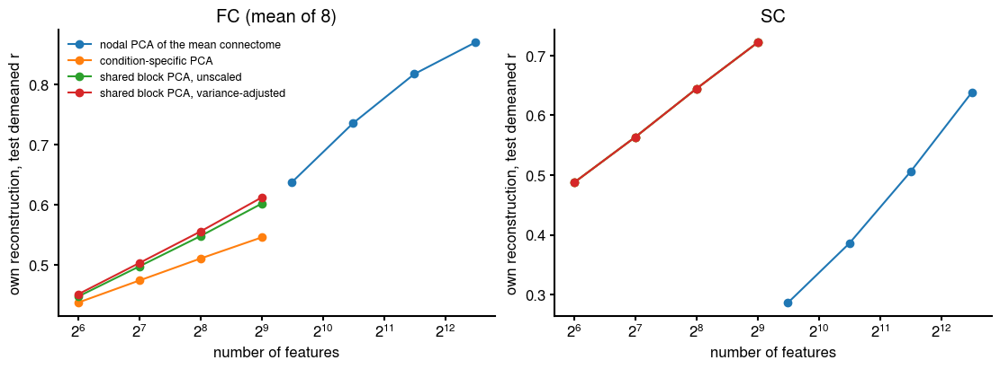

In [7]:
ceil = A.seed_mean(df[df.hyp == "ceiling"].assign(group=lambda d: np.where(d.source == "SC", "SC", "FC (mean of 8)")),
                   ["rep", "size", "group"], metrics=("demeaned_pearson",))
tab = ceil.pivot_table(index=["rep", "size"], columns="group", values="demeaned_pearson_mean")
display(tab)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for j, grp in enumerate(["FC (mean of 8)", "SC"]):
    for rep in ["R0", "R1", "R2", "R3"]:
        t = ceil[(ceil.rep == rep) & (ceil.group == grp)]
        x = t["size"].astype(int) * (360 if rep == "R0" else 1)
        ax[j].plot(x, t.demeaned_pearson_mean, "o-", label=A.REP_LABEL[rep])
    ax[j].set_xscale("log", base=2); ax[j].set_xlabel("number of features"); ax[j].set_title(grp)
    ax[j].set_ylabel("own reconstruction, test demeaned r")
ax[0].legend(fontsize=9)
plt.show()

### 2.2 Transfer methods

**Ridge (PCA representations).** $T_{a\to b} = \arg\min_T \lVert Z^b - Z^a T \rVert_F^2 + \alpha \lVert T \rVert_F^2$,
$\alpha = \alpha_{\mathrm{rel}} \cdot \overline{\sigma^2}(Z^a)$, $\alpha_{\mathrm{rel}} \in \{10^{-3}, \dots, 10^{4}\}$;
the size ($k$ or $q$, shared by source and target) and $\alpha_{\mathrm{rel}}$ are chosen on validation average rank.

**Conditional Gaussian (PCA representations).** Model $(z^a, z^b)$ as jointly Gaussian with the Ledoit–Wolf shrunk
covariance $\hat\Sigma = (1-\rho) S + \rho \mu I$ ($S$ the sample covariance of the concatenated train codes,
$\mu = \mathrm{tr}(S)/p$, $\rho$ the Ledoit–Wolf intensity). The prediction is the conditional mean

$$ \mathbb{E}[z^b \mid z^a] = \hat\Sigma_{ba} \hat\Sigma_{aa}^{-1} z^a = S_{ba}\Big(S_{aa} + \tfrac{\rho \mu}{1-\rho} I\Big)^{-1} z^a , $$

i.e. a ridge whose penalty is set analytically by the shrinkage, not on validation. Only the size is chosen on val.
(Its conditional covariance makes it a generative model; the distributional comparison belongs to spec v4 E4.)

**CCA with ridge decoders (native space).** Encode the source, $g_i^a = z_i^a A_a$; then a ridge decoder from the
source's train encodings to the target's edges, $\hat x_i^b = \bar x^b + g_i^a B_{a \to b}$,
$B_{a\to b} = \arg\min_B \lVert R^b - G^a B \rVert_F^2 + \alpha \lVert B \rVert_F^2$ (fitted on the full-rank target
codes, identical to fitting on the edges). $(d, \lambda)$ is chosen once per seed on the mean validation average rank
over all 72 pairs ($d \in \{8, \dots, 256\}$, $\lambda \in \{0.01, \dots, 100\}$); $\alpha$ per pair.

**References.** *Copy* (FC → FC): $\hat x_i^b = \bar x^b + r_i^a$. *Own reconstruction* (ceiling, above).

Selected hyperparameters:

In [8]:
sel = pd.DataFrame({s: {"CCA d": v["CCA"]["d"], "CCA λ": v["CCA"]["lambda_rel"], "CCA val avg rank": v["CCA"]["val_mean_avg_rank"],
                        "CCA-256 d": v["CCA-256"]["d"], "CCA-256 λ": v["CCA-256"]["lambda_rel"],
                        "best PCA (val)": max(v["H1_pca_val"], key=v["H1_pca_val"].get),
                        **{f"{r} val avg rank": x for r, x in v["H1_pca_val"].items()}} for s, v in SEL.items()}).T
sel.index.name = "seed"
display(sel)
h1 = A.h1_frame(df)
display(h1[h1.model.isin(["ridge", "cond_gauss"])].groupby(["rep", "model"])["size"].agg(lambda s: s.value_counts().to_dict())
        .rename("chosen size: count over pairs × seeds").to_frame())

,CCA d,CCA λ,CCA val avg rank,CCA-256 d,CCA-256 λ,best PCA (val),R0 val avg rank,R1 val avg rank,R2 val avg rank,R3 val avg rank
seed,,,,,,,,,,
0,32,0.1,0.7961,32,0.1,R3,0.7656,0.7767,0.769,0.7772
1,32,0.01,0.79,64,0.1,R3,0.7523,0.7657,0.7598,0.769
2,64,0.1,0.7951,32,0.1,R3,0.7524,0.7669,0.7583,0.7683
3,64,0.1,0.7926,64,0.1,R3,0.7531,0.7679,0.7591,0.7695
4,32,0.1,0.7916,32,0.1,R3,0.7564,0.7688,0.7621,0.7717


chosen size: count over pairs × seeds
rep model                                                     
R0  cond_gauss          {16.0: 276, 8.0: 49, 2.0: 20, 4.0: 15}
    ridge              {16.0: 194, 8.0: 132, 4.0: 24, 2.0: 10}
R1  cond_gauss     {512.0: 286, 256.0: 50, 128.0: 18, 64.0: 6}
    ridge          {512.0: 282, 256.0: 59, 128.0: 17, 64.0: 2}
R2  cond_gauss  {256.0: 123, 512.0: 121, 128.0: 100, 64.0: 16}
    ridge          {512.0: 258, 256.0: 74, 128.0: 26, 64.0: 2}
R3  cond_gauss    {256.0: 142, 128.0: 99, 512.0: 93, 64.0: 26}
    ridge          {512.0: 226, 256.0: 99, 128.0: 30, 64.0: 5}

<a id="3-h1"></a>
## 3. H1 — does a CCA co-embedding give more accurate and identifiable maps than the PCA representations?

**Hypothesis.** For every ordered pair of the nine views (72 pairs, including SC → FC and FC → SC), the full-rank
multiview CCA with a ridge decoder beats the best PCA representation (the one with the best validation average rank,
per seed) on test average rank, without losing demeaned r. **Support rule:** CCA ahead in ≥ 4 / 5 seeds on average
rank (mean over the 72 pairs) and mean demeaned r not lower by more than 0.005.

In [9]:
summ, con, per_pair, BP = A.h1_tables(df, SEL)
show = summ.assign(**{lab: [A.fmt(m, s) for m, s in zip(summ[f"{k}_mean"], summ[f"{k}_se"])] for k, lab in A.METRICS.items()})
display(show.pivot_table(index="label", columns="block", values="average rank", aggfunc="first")
        [["all", "FC -> FC", "SC -> FC", "FC -> SC"]].sort_values("all", ascending=False))
display(show.pivot_table(index="label", columns="block", values="demeaned r", aggfunc="first")
        [["all", "FC -> FC", "SC -> FC", "FC -> SC"]].sort_values("all", ascending=False))

block,all,FC -> FC,SC -> FC,FC -> SC
label,,,,
CCA on 256 variance-adjusted block-PCA codes,0.8111 ± 0.0027,0.8313 ± 0.0031,0.6864 ± 0.0049,0.7937 ± 0.0015
CCA (full rank),0.7932 ± 0.0022,0.8120 ± 0.0021,0.6679 ± 0.0057,0.7876 ± 0.0018
"shared block PCA, variance-adjusted · ridge",0.7663 ± 0.0017,0.7847 ± 0.0015,0.6750 ± 0.0047,0.7293 ± 0.0047
condition-specific PCA · cond. Gaussian,0.7659 ± 0.0016,0.7840 ± 0.0017,0.6717 ± 0.0045,0.7333 ± 0.0027
condition-specific PCA · ridge,0.7657 ± 0.0014,0.7804 ± 0.0016,0.6884 ± 0.0036,0.7398 ± 0.0025
"shared block PCA, unscaled · ridge",0.7578 ± 0.0014,0.7756 ± 0.0015,0.6696 ± 0.0030,0.7215 ± 0.0037
nodal PCA of the mean connectome · ridge,0.7492 ± 0.0018,0.7664 ± 0.0015,0.6718 ± 0.0042,0.7068 ± 0.0041
"shared block PCA, variance-adjusted · cond. Gaussian",0.7466 ± 0.0012,0.7671 ± 0.0012,0.6226 ± 0.0050,0.7276 ± 0.0039
"shared block PCA, unscaled · cond. Gaussian",0.7326 ± 0.0017,0.7564 ± 0.0017,0.6225 ± 0.0053,0.6764 ± 0.0041


block,all,FC -> FC,SC -> FC,FC -> SC
label,,,,
CCA (full rank),0.0913 ± 0.0014,0.0977 ± 0.0013,0.0422 ± 0.0019,0.0958 ± 0.0031
CCA on 256 variance-adjusted block-PCA codes,0.0885 ± 0.0010,0.0943 ± 0.0015,0.0430 ± 0.0015,0.0936 ± 0.0026
"shared block PCA, variance-adjusted · ridge",0.0872 ± 0.0010,0.0960 ± 0.0011,0.0450 ± 0.0010,0.0682 ± 0.0019
"shared block PCA, unscaled · ridge",0.0837 ± 0.0009,0.0921 ± 0.0011,0.0435 ± 0.0008,0.0649 ± 0.0017
"shared block PCA, variance-adjusted · cond. Gaussian",0.0833 ± 0.0008,0.0923 ± 0.0010,0.0353 ± 0.0017,0.0682 ± 0.0018
"shared block PCA, unscaled · cond. Gaussian",0.0777 ± 0.0009,0.0863 ± 0.0011,0.0333 ± 0.0018,0.0614 ± 0.0016
condition-specific PCA · cond. Gaussian,0.0767 ± 0.0009,0.0833 ± 0.0011,0.0371 ± 0.0011,0.0697 ± 0.0015
condition-specific PCA · ridge,0.0757 ± 0.0009,0.0816 ± 0.0010,0.0412 ± 0.0007,0.0696 ± 0.0013
nodal PCA of the mean connectome · ridge,0.0722 ± 0.0010,0.0802 ± 0.0010,0.0408 ± 0.0010,0.0474 ± 0.0017


findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Fon

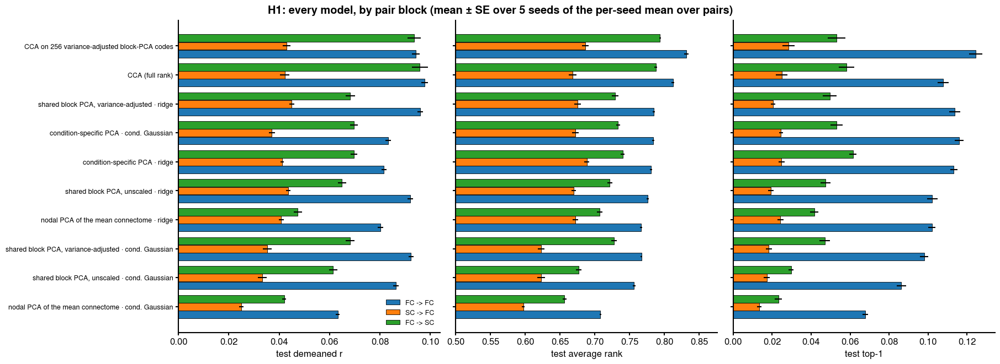

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6.5), layout="constrained")
labs = (summ[summ.block == "all"].sort_values("avg_rank_mean").label.tolist())
for ax, (k, lab) in zip(axes, A.METRICS.items()):
    for j, blk in enumerate(["FC -> FC", "SC -> FC", "FC -> SC"]):
        t = summ[summ.block == blk].set_index("label").reindex(labs)
        y = np.arange(len(labs)) + (j - 1) * 0.27
        ax.barh(y, t[f"{k}_mean"], xerr=t[f"{k}_se"], height=0.26, label=blk, edgecolor="black", lw=0.6)
    ax.set_yticks(range(len(labs)), labs if ax is axes[0] else [""] * len(labs), fontsize=9)
    ax.set_xlabel(f"test {lab}")
    ax.set_xlim(0.5 if k == "avg_rank" else 0, None)
    if k == "avg_rank":
        ax.axvline(0.5, color="grey", lw=0.8, ls=":")
axes[0].legend(loc="lower right", fontsize=9)
fig.suptitle("H1: every model, by pair block (mean ± SE over 5 seeds of the per-seed mean over pairs)", fontweight="bold")
plt.show()

In [11]:
verdict, c = A.verdict(con)
display(Markdown(f"**H1 (all 72 pairs): {verdict}.** Per-block verdicts: " + "; ".join(
    f"{b}: {A.verdict(con, b)[0]}" for b in ("FC -> FC", "SC -> FC", "FC -> SC"))))
t = con.copy()
t["Δ (mean ± SE)"] = [A.fmt(m, s) for m, s in zip(t["mean"], t["se"])]
t["seeds > 0"] = t.n_pos.astype(str) + " / " + t.n.astype(str)
display(t.pivot_table(index=["contrast", "metric"], columns="block", values="Δ (mean ± SE)", aggfunc="first")
        [["all", "FC -> FC", "SC -> FC", "FC -> SC"]])
display(t.pivot_table(index=["contrast", "metric"], columns="block", values="seeds > 0", aggfunc="first")
        [["all", "FC -> FC", "SC -> FC", "FC -> SC"]])

**H1 (all 72 pairs): supported.** Per-block verdicts: FC -> FC: supported; SC -> FC: not supported; FC -> SC: supported

block                                                                            all          FC -> FC          SC -> FC          FC -> SC
contrast                                          metric                                                                                  
CCA − CCA on 256 block-PCA codes                  avg_rank          -0.0178 ± 0.0017  -0.0194 ± 0.0017  -0.0185 ± 0.0072  -0.0061 ± 0.0017
CCA − best PCA (ridge)                            avg_rank           0.0269 ± 0.0010   0.0273 ± 0.0008  -0.0071 ± 0.0068   0.0583 ± 0.0041
                                                  demeaned_pearson   0.0041 ± 0.0009   0.0017 ± 0.0008  -0.0028 ± 0.0013   0.0277 ± 0.0018
                                                  top1_acc          -0.0031 ± 0.0014  -0.0059 ± 0.0013   0.0045 ± 0.0028   0.0085 ± 0.0025
CCA − condition-specific PCA (ridge)              avg_rank           0.0276 ± 0.0010   0.0316 ± 0.0011  -0.0204 ± 0.0062   0.0478 ± 0.0015
CCA − nodal PCA of the mean connectome (ridge)    avg_rank           0.0440 ± 0.0008   0.0456 ± 0.0011  -0.0038 ± 0.0047   0.0808 ± 0.0034
CCA − shared block PCA, unscaled (ridge)          avg_rank           0.0354 ± 0.0009   0.0364 ± 0.0009  -0.0017 ± 0.0054   0.0661 ± 0.0032
CCA − shared block PCA, variance-adjusted (ridge) avg_rank           0.0269 ± 0.0010   0.0273 ± 0.0008  -0.0071 ± 0.0068   0.0583 ± 0.0041

block                                                                 all FC -> FC SC -> FC FC -> SC
contrast                                          metric                                            
CCA − CCA on 256 block-PCA codes                  avg_rank          0 / 5    0 / 5    1 / 5    0 / 5
CCA − best PCA (ridge)                            avg_rank          5 / 5    5 / 5    2 / 5    5 / 5
                                                  demeaned_pearson  5 / 5    4 / 5    1 / 5    5 / 5
                                                  top1_acc          1 / 5    0 / 5    3 / 5    5 / 5
CCA − condition-specific PCA (ridge)              avg_rank          5 / 5    5 / 5    0 / 5    5 / 5
CCA − nodal PCA of the mean connectome (ridge)    avg_rank          5 / 5    5 / 5    2 / 5    5 / 5
CCA − shared block PCA, unscaled (ridge)          avg_rank          5 / 5    5 / 5    2 / 5    5 / 5
CCA − shared block PCA, variance-adjusted (ridge) avg_rank          5 / 5    5 / 5    2 / 5    5 / 5

findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Fon

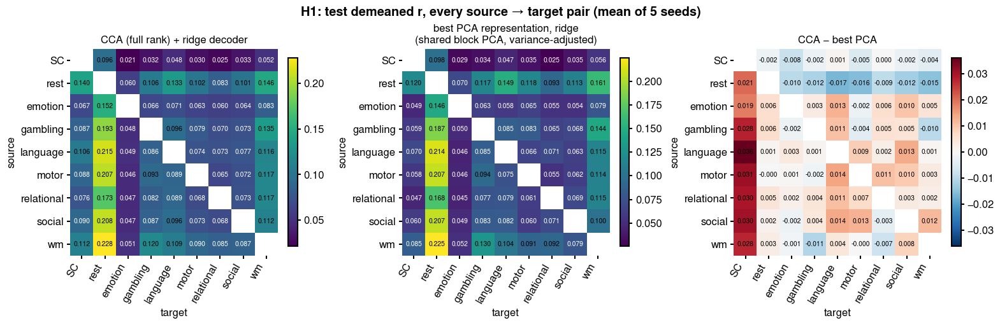

findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Fon

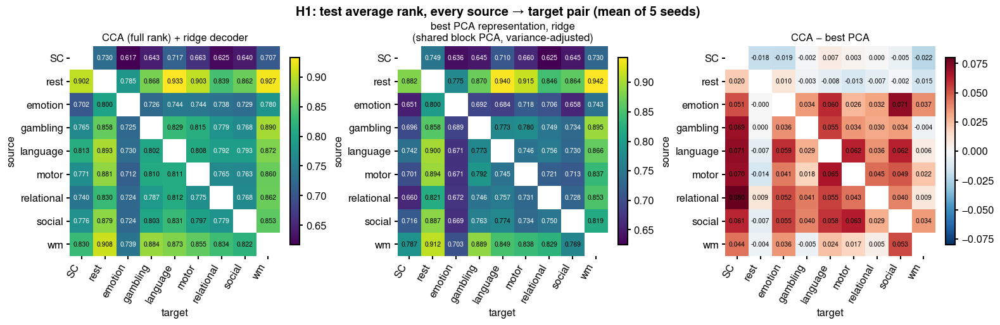

findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Fon

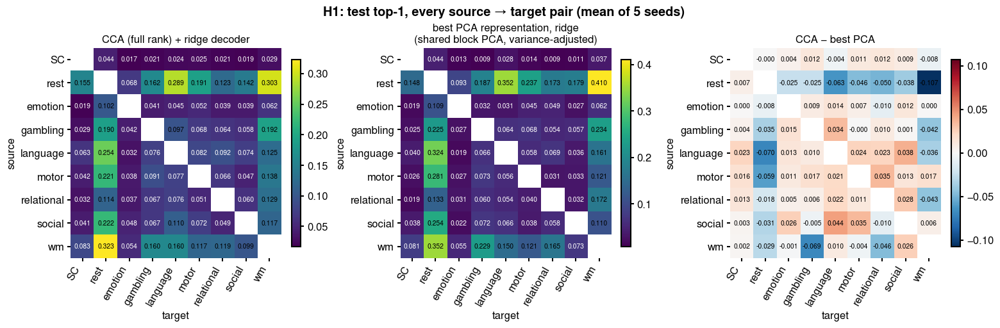

Pairs where CCA's seed-mean average rank exceeds the best PCA's: FC -> FC: 43 / 56, FC -> SC: 8 / 8, SC -> FC: 3 / 8

In [12]:
cca = h1[(h1.model == "cca_ridge") & (h1.rep == "CCA")]
pca = h1[(h1.model == "ridge") & (h1.rep == h1.seed.map(BP))]
for k, lab in A.METRICS.items():
    Mc, Mp = A.pair_matrix(df, k, cca), A.pair_matrix(df, k, pca)
    A.heatmaps([Mc, Mp, Mc - Mp], ["CCA (full rank) + ridge decoder", f"best PCA representation, ridge\n({', '.join(sorted({A.REP_LABEL[r] for r in BP.values()}))})",
               "CCA − best PCA"], f"H1: test {lab}, every source → target pair (mean of 5 seeds)",
               diverging=[False, False, True], fmt_="{:.3f}")
    plt.show()
wins = (per_pair[("d_avg_rank", "mean")] > 0).groupby(level="block").agg(["sum", "size"])
display(Markdown("Pairs where CCA's seed-mean average rank exceeds the best PCA's: " +
                 ", ".join(f"{b}: {int(r['sum'])} / {int(r['size'])}" for b, r in wins.iterrows())))

**Result: H1 supported over all 72 pairs, driven by FC → FC and FC → SC; not for SC → FC.**

- **Over all pairs**, full-rank CCA with a ridge decoder beats the best PCA representation on average rank by
  +0.027 ± 0.001 (5 / 5 seeds), with a small gain in demeaned r (+0.004 ± 0.001, 5 / 5). Top-1 is level (−0.003 ± 0.001).
  The best PCA representation is R3, the variance-adjusted block PCA, on every seed.
- **By block:**
  - FC → FC: +0.027 average rank (5 / 5), +0.002 demeaned r.
  - FC → SC: the largest gain, +0.058 average rank and +0.028 demeaned r (5 / 5 on both).
  - SC → FC: no gain (−0.007 ± 0.007, 2 / 5). Every representation is near the SC → FC floor (demeaned r ≈ 0.04, as
    in spec v4 E2.1).
- **Ordering of the PCA representations:** R3 > R1 ≈ R2 > R0 on average rank. Variance-adjusted pooling (R3) is the
  best transfer space, which fits spec v4 D2.
- **The nodal representation (R0)** reconstructs its own view best: its 5,760 features exceed 512 PCA codes. It is
  still the worst transfer space: a basis fixed by the group mean does not align with how subjects vary.
- **The conditional Gaussian** never beats validation-tuned ridge. Its analytic Ledoit–Wolf penalty is not tuned for
  identification.
- **Truncation helps identification.** CCA on 256 R3 codes (CCA-256, the latent of E1 / E4) identifies better than
  full-rank CCA: average rank +0.018 overall, 0 / 5 seeds favour full rank. It is less accurate (demeaned r 0.089 vs
  0.091). Discarding the low-variance tail is a useful regulariser for identification; ridge alone does not replace it.
- **Copying still wins FC → FC identification.** The source residual itself (average rank 0.845, top-1 0.25) beats
  every learned FC → FC map. The individual signal that identifies a subject across conditions sits largely outside
  what a linear map fit on 659 subjects transfers (spec v4 E4.0).

<a id="4-h2"></a>
## 4. H2 — does a consensus of the other views reconstruct a held-out view better than any single view?

For each held-out view $b$ (8 FC conditions and SC) and its source set $\mathcal{S}$ (**other8**: all other views,
including SC for FC targets; **other7**: the other FC conditions only):
- **CCA-agg:** $\bar g_i = \frac{1}{|\mathcal{S}|} \sum_{a \in \mathcal{S}} g_i^a$ (the encodings estimate the same
  latent, so averaging reduces the noise of each estimate), ridge decoder to $b$;
- **CCA-cat:** $[g_i^a]_{a \in \mathcal{S}} \in \mathbb{R}^{|\mathcal{S}| d}$, ridge decoder (the decoder may weight
  sources differently);
- **best single source (CCA):** the source in $\mathcal{S}$ with the best validation average rank in H1;
- **ridge, concatenated codes:** each PCA representation's source codes concatenated, size and penalty on val;
- **copy:** no fitting; the residuals of the FC sources (each minus its condition's train mean) are averaged and added
  to the target's train mean. SC is never averaged in (its residual is a different quantity), so other8 and other7
  copy are identical, and there is no copy for the SC target.

**Support rule:** CCA-agg or CCA-cat ahead of both the best single source and the best concatenated PCA ridge (the
representation with the best validation score) in ≥ 4 / 5 seeds on average rank (mean over held-out views), demeaned r
not lower by more than 0.005.

In [13]:
s2, t2, c2 = A.h2_tables(df)
s2v = s2.assign(**{lab: [A.fmt(m, s) for m, s in zip(s2[f"{k}_mean"], s2[f"{k}_se"])] for k, lab in A.METRICS.items()})
display(s2v.set_index(["setting", "label"])[list(A.METRICS.values())].sort_index())
c2v = c2.assign(**{"Δ (mean ± SE)": [A.fmt(m, s) for m, s in zip(c2["mean"], c2["se"])],
                   "seeds > 0": c2.n_pos.astype(str) + " / " + c2.n.astype(str)})
display(c2v.set_index(["setting", "contrast", "metric"])[["Δ (mean ± SE)", "seeds > 0"]])

demeaned r     average rank            top-1
setting label                                                                                                
other7  CCA-agg                                             0.1454 ± 0.0022  0.9156 ± 0.0022  0.2835 ± 0.0100
        CCA-cat                                             0.1449 ± 0.0028  0.9171 ± 0.0028  0.2824 ± 0.0117
        best single source (CCA)                            0.1197 ± 0.0014  0.8777 ± 0.0019  0.1950 ± 0.0093
        copy: mean of the other FC conditions' residuals    0.2084 ± 0.0013  0.9956 ± 0.0004  0.8895 ± 0.0048
        ridge on concatenated codes: condition-specific...  0.1219 ± 0.0015  0.8853 ± 0.0015  0.2469 ± 0.0058
        ridge on concatenated codes: nodal PCA of the m...  0.1170 ± 0.0012  0.8613 ± 0.0026  0.2021 ± 0.0071
        ridge on concatenated codes: shared block PCA, ...  0.1333 ± 0.0016  0.8694 ± 0.0009  0.2084 ± 0.0049
        ridge on concatenated codes: shared block PCA, ...  0.1462 ± 0.0014  0.8974 ± 0.0007  0.2776 ± 0.0048
other8  CCA-agg                                             0.1425 ± 0.0017  0.9117 ± 0.0022  0.2531 ± 0.0073
        CCA-cat                                             0.1420 ± 0.0026  0.9143 ± 0.0027  0.2571 ± 0.0105
        best single source (CCA)                            0.1220 ± 0.0014  0.8804 ± 0.0022  0.1905 ± 0.0077
        copy: mean of the other FC conditions' residuals    0.2084 ± 0.0013  0.9956 ± 0.0004  0.8895 ± 0.0048
        ridge on concatenated codes: condition-specific...  0.1192 ± 0.0011  0.8800 ± 0.0012  0.2333 ± 0.0042
        ridge on concatenated codes: nodal PCA of the m...  0.1106 ± 0.0017  0.8506 ± 0.0024  0.1875 ± 0.0078
        ridge on concatenated codes: shared block PCA, ...  0.1281 ± 0.0015  0.8626 ± 0.0009  0.1923 ± 0.0029
        ridge on concatenated codes: shared block PCA, ...  0.1397 ± 0.0012  0.8885 ± 0.0017  0.2439 ± 0.0045

Δ (mean ± SE) seeds > 0
setting contrast                        metric                                      
other8  CCA-agg − best single source    avg_rank           0.0313 ± 0.0018     5 / 5
        CCA-agg − best PCA concatenated avg_rank           0.0232 ± 0.0037     5 / 5
        CCA-agg − best single source    demeaned_pearson   0.0205 ± 0.0017     5 / 5
        CCA-agg − best PCA concatenated demeaned_pearson   0.0027 ± 0.0015     4 / 5
        CCA-agg − best single source    top1_acc           0.0626 ± 0.0118     5 / 5
        CCA-agg − best PCA concatenated top1_acc           0.0092 ± 0.0091     4 / 5
        CCA-cat − best single source    avg_rank           0.0339 ± 0.0017     5 / 5
        CCA-cat − best PCA concatenated avg_rank           0.0258 ± 0.0040     5 / 5
        CCA-cat − best single source    demeaned_pearson   0.0199 ± 0.0020     5 / 5
        CCA-cat − best PCA concatenated demeaned_pearson   0.0022 ± 0.0021     3 / 5
        CCA-cat − best single source    top1_acc           0.0666 ± 0.0123     5 / 5
        CCA-cat − best PCA concatenated top1_acc           0.0132 ± 0.0104     4 / 5
other7  CCA-agg − best single source    avg_rank           0.0379 ± 0.0024     5 / 5
        CCA-agg − best PCA concatenated avg_rank           0.0183 ± 0.0025     5 / 5
        CCA-agg − best single source    demeaned_pearson   0.0257 ± 0.0022     5 / 5
        CCA-agg − best PCA concatenated demeaned_pearson  -0.0008 ± 0.0020     2 / 5
        CCA-agg − best single source    top1_acc           0.0885 ± 0.0137     5 / 5
        CCA-agg − best PCA concatenated top1_acc           0.0059 ± 0.0116     3 / 5
        CCA-cat − best single source    avg_rank           0.0394 ± 0.0025     5 / 5
        CCA-cat − best PCA concatenated avg_rank           0.0197 ± 0.0031     5 / 5
        CCA-cat − best single source    demeaned_pearson   0.0252 ± 0.0024     5 / 5
        CCA-cat − best PCA concatenated demeaned_pearson  -0.0012 ± 0.0024     2 / 5
        CCA-cat − best single source    top1_acc           0.0874 ± 0.0141     5 / 5
        CCA-cat − best PCA concatenated top1_acc           0.0048 ± 0.0126     3 / 5

findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Fon

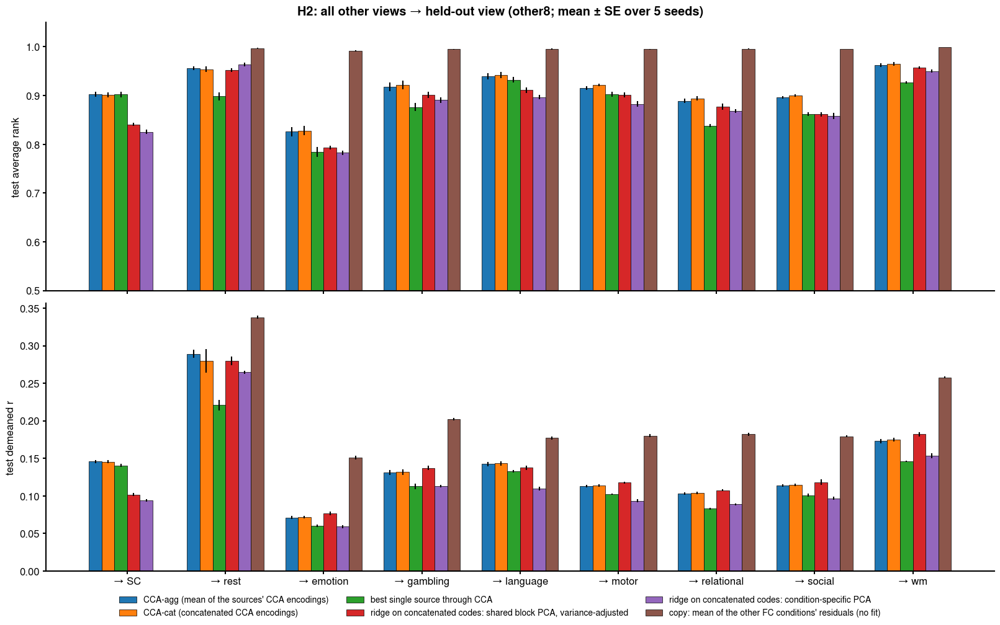

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10), layout="constrained", sharex=True)
models = ["cca_agg", "cca_cat", "cca_best_single", "ridge_cat (R3)", "ridge_cat (R1)", "copy"]
lab = {"cca_agg": "CCA-agg (mean of the sources' CCA encodings)", "cca_cat": "CCA-cat (concatenated CCA encodings)",
       "cca_best_single": "best single source through CCA",
       "ridge_cat (R3)": f"ridge on concatenated codes: {A.REP_LABEL['R3']}",
       "ridge_cat (R1)": f"ridge on concatenated codes: {A.REP_LABEL['R1']}",
       "copy": "copy: mean of the other FC conditions' residuals (no fit)"}
h2 = df[df.hyp == "H2"].copy()
h2["m"] = np.where(h2.model == "ridge_cat", h2.model + " (" + h2.rep + ")", h2.model)
for ax, k in zip(axes, ["avg_rank", "demeaned_pearson"]):
    t = A.seed_mean(h2[h2.setting == "other8"], ["target", "m"], metrics=(k,))
    for j, m in enumerate(models):
        u = t[t.m == m].set_index("target").reindex(VIEWS)
        x = np.arange(len(VIEWS)) + (j - len(models) / 2 + 0.5) * 0.13
        ax.bar(x, u[f"{k}_mean"], yerr=u[f"{k}_se"], width=0.13, label=lab[m], edgecolor="black", lw=0.5)
    ax.set_ylabel(f"test {A.METRICS[k]}")
    ax.set_ylim(0.5 if k == "avg_rank" else 0, None)
axes[1].set_xticks(range(len(VIEWS)), [f"→ {v}" for v in VIEWS])
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="outside lower center", ncol=3, fontsize=10, frameon=False)
fig.suptitle("H2: all other views → held-out view (other8; mean ± SE over 5 seeds)", fontweight="bold")
plt.show()

**Result: H2 supported.** Pooling the CCA encodings of the other views beats both comparators on average rank in
every seed:
- **vs the best single source through CCA:** +0.031 to +0.039 average rank and +0.020 to +0.026 demeaned r, depending
  on setting and model (5 / 5).
- **vs the best concatenated PCA ridge** (R3 on every seed): +0.018 to +0.026 average rank (5 / 5), with demeaned r
  level (−0.001 to +0.003).

**Averaging vs concatenating:**
- Averaging (CCA-agg) and concatenating (CCA-cat) the encodings perform the same (average rank 0.912–0.917), so source
  weights learned by the decoder add nothing. This matches the latent's design: each view's encoding estimates the same
  subject score.
- Concatenated PCA ridge is competitive on demeaned r because R3 codes keep more detail than a 32–64-dimensional latent.

**Effect of SC:** adding SC as an eighth source changes nothing (other8 vs other7, average rank 0.912 vs 0.916). SC is
predicted from the eight FC views (average rank 0.90, demeaned r 0.145) far better than from any PCA concatenation
(0.84) and about as well as from the best single view (0.90).

**Reference:** copying the mean residual of the other conditions remains far ahead (average rank 0.996, top-1 0.89),
for the reason given in H1.

<a id="5-h3"></a>
## 5. H3 — does a composite loss improve the CCA decoders?

Every CCA decoder of H1 (72 pairs) and H2 (CCA-agg and CCA-cat per held-out view and setting) is a linear map
$\hat x = \bar x^b + g W$. Its ridge solution minimises $\mathcal{L}_{\mathrm{ridge}} = \mathrm{MSE} + \frac{\alpha}{nE} \lVert W \rVert_F^2$.
H3 retrains $W$ by gradient descent on

$$ \mathcal{L} = \mathrm{MSE} + \frac{\alpha}{nE} \lVert W \rVert_F^2 + \sum_{t} w_t \frac{\mathcal{L}_t}{c_t}, \qquad c_t = \frac{\overline{|\mathcal{L}_t|}}{\overline{\mathrm{MSE}}}\Big|_{W_{\mathrm{ridge}}} , $$

with the terms of the composite-loss protocol (`scripts/experiments/composite_loss/composite_loss.md`), each computed on
a batch of $B = 64$ subjects:
- **Var-match (VM):** $\big((\sigma^2_y - \sigma^2_{\hat y}) / \sigma^2_y\big)^2$, variance over the batch and edges;
- **Demeaned corr-eye (CEdm):** $\lVert \mathrm{corr}(y - \bar x, \hat y - \bar x) - I \rVert_F$ over the $B \times B$
  subject correlation matrix (pushes each prediction towards its own subject's residual and away from the others');
- **Neighbour distance (ND):** $\overline{d(y_i, \hat y_i)} - \overline{\min_{j \neq i} d}$ (own distance minus nearest
  other).

Grid v3's $2 \times 2 \times 2$ factorial at $w_t = 0.5$ (eight combinations, including MSE only). $W$ starts at the
ridge solution (Adam, cosine schedule, 300 epochs); each combination keeps the weights with the best validation average
rank, epoch 0 (the ridge solution) included. **Gate G1:** the MSE-only decoders reproduce the ridge decoders.
**Support rule:** a combination raises test average rank over the ridge decoder in ≥ 4 / 5 seeds (mean over the
decoders in scope), demeaned r not lower by more than 0.005.

In [15]:
if len(H3):
    D3, S3 = A.h3_tables(H3)
    S3v = S3.assign(**{f"Δ {lab}": [A.fmt(m, s) for m, s in zip(S3[f"d_{k}_mean"], S3[f"d_{k}_se"])] for k, lab in A.METRICS.items()},
                    combination=S3.combo.map(A.COMBO_LABEL))
    display(S3v.set_index(["group", "combination"])[[f"Δ {lab}" for lab in A.METRICS.values()] + ["n_pos_rank", "supported"]])
else:
    print("H3 results not available")

Δ demeaned r    Δ average rank           Δ top-1  n_pos_rank       supported
group    combination                                                                                    
all      +VM +CEdm +ND  -0.0059 ± 0.0004   0.0213 ± 0.0009   0.0280 ± 0.0014           5              no
         +CEdm          -0.0108 ± 0.0007   0.0406 ± 0.0013   0.0599 ± 0.0024           5              no
         +CEdm +ND      -0.0060 ± 0.0004   0.0223 ± 0.0008   0.0294 ± 0.0012           5              no
         MSE            -0.0000 ± 0.0000   0.0000 ± 0.0000   0.0000 ± 0.0001           4  reference (G1)
         +ND            -0.0030 ± 0.0002   0.0102 ± 0.0010   0.0184 ± 0.0016           5             yes
         +VM            -0.0001 ± 0.0001  -0.0001 ± 0.0001   0.0016 ± 0.0003           1              no
         +VM +CEdm      -0.0098 ± 0.0006   0.0352 ± 0.0010   0.0479 ± 0.0015           5              no
         +VM +ND        -0.0031 ± 0.0002   0.0094 ± 0.0011   0.0174 ± 0.0018           5             yes
FC -> FC +VM +CEdm +ND  -0.0070 ± 0.0006   0.0244 ± 0.0016   0.0215 ± 0.0020           5              no
         +CEdm          -0.0128 ± 0.0008   0.0490 ± 0.0013   0.0516 ± 0.0020           5              no
         +CEdm +ND      -0.0071 ± 0.0006   0.0255 ± 0.0015   0.0226 ± 0.0018           5              no
         MSE            -0.0000 ± 0.0000  -0.0000 ± 0.0000  -0.0000 ± 0.0001           3  reference (G1)
         +ND            -0.0032 ± 0.0002   0.0107 ± 0.0011   0.0114 ± 0.0011           5             yes
         +VM            -0.0000 ± 0.0000  -0.0002 ± 0.0000   0.0000 ± 0.0001           0              no
         +VM +CEdm      -0.0120 ± 0.0008   0.0428 ± 0.0015   0.0435 ± 0.0026           5              no
         +VM +ND        -0.0032 ± 0.0002   0.0098 ± 0.0011   0.0101 ± 0.0013           5             yes
FC -> SC +VM +CEdm +ND  -0.0036 ± 0.0008   0.0006 ± 0.0003   0.0016 ± 0.0007           4             yes
         +CEdm          -0.0036 ± 0.0011   0.0003 ± 0.0002   0.0012 ± 0.0008           4             yes
         +CEdm +ND      -0.0037 ± 0.0007   0.0007 ± 0.0003   0.0014 ± 0.0010           5             yes
         MSE             0.0000 ± 0.0000   0.0000 ± 0.0000  -0.0001 ± 0.0001           2  reference (G1)
         +ND            -0.0019 ± 0.0002   0.0010 ± 0.0002   0.0026 ± 0.0011           5             yes
         +VM            -0.0001 ± 0.0000   0.0000 ± 0.0000   0.0008 ± 0.0004           3              no
         +VM +CEdm      -0.0034 ± 0.0010   0.0005 ± 0.0002   0.0005 ± 0.0007           4             yes
         +VM +ND        -0.0021 ± 0.0004   0.0012 ± 0.0003   0.0026 ± 0.0011           5             yes
SC -> FC +VM +CEdm +ND  -0.0041 ± 0.0006   0.0492 ± 0.0046   0.0125 ± 0.0012           5             yes
         +CEdm          -0.0047 ± 0.0008   0.0612 ± 0.0033   0.0158 ± 0.0020           5             yes
         +CEdm +ND      -0.0041 ± 0.0006   0.0493 ± 0.0046   0.0124 ± 0.0012           5             yes
         MSE            -0.0000 ± 0.0000   0.0000 ± 0.0000  -0.0001 ± 0.0001           3  reference (G1)
         +ND            -0.0008 ± 0.0003   0.0106 ± 0.0008   0.0016 ± 0.0008           5             yes
         +VM            -0.0000 ± 0.0000   0.0000 ± 0.0001  -0.0001 ± 0.0001           1              no
         +VM +CEdm      -0.0047 ± 0.0008   0.0605 ± 0.0035   0.0158 ± 0.0023           5             yes
         +VM +ND        -0.0008 ± 0.0003   0.0105 ± 0.0008   0.0019 ± 0.0008           5             yes
other7   +VM +CEdm +ND  -0.0052 ± 0.0004   0.0154 ± 0.0012   0.0476 ± 0.0028           5              no
         +CEdm          -0.0113 ± 0.0008   0.0333 ± 0.0019   0.1025 ± 0.0065           5              no
         +CEdm +ND      -0.0053 ± 0.0004   0.0164 ± 0.0011   0.0506 ± 0.0022           5              no
         MSE            -0.0000 ± 0.0000   0.0000 ± 0.0000   0.0004 ± 0.0002           4  reference (G1)
         +ND            -0.0036 ± 0.00

findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Fon

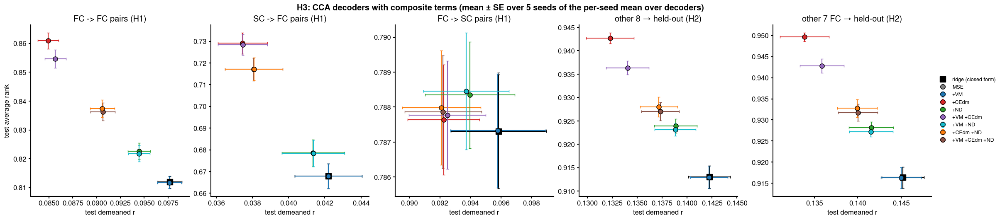

In [16]:
groups = ["FC -> FC", "SC -> FC", "FC -> SC", "other8", "other7"]
combos = ["ridge"] + list(CFG["composite"]["combos"])
colors = dict(zip(combos, ["#000000", "#7f7f7f", "#1f77b4", "#d62728", "#2ca02c", "#9467bd", "#17becf", "#ff7f0e", "#8c564b"]))
H3g = H3.assign(group=np.where(H3.hyp == "H1", [("SC -> FC" if s == "SC" else "FC -> SC" if t == "SC" else "FC -> FC")
                                                for s, t in zip(H3.source, H3.target)], H3.setting))
fig, axes = plt.subplots(1, len(groups), figsize=(24, 5.2), layout="constrained")
for ax, g in zip(axes, groups):
    t = A.seed_mean(H3g[H3g.group == g], ["combo"], metrics=("demeaned_pearson", "avg_rank"))
    for _, r in t.iterrows():
        ax.errorbar(r.demeaned_pearson_mean, r.avg_rank_mean, xerr=r.demeaned_pearson_se, yerr=r.avg_rank_se,
                    fmt="o" if r.combo != "ridge" else "s", ms=8 if r.combo != "ridge" else 10, color=colors[r.combo],
                    mec="black", label=A.COMBO_LABEL[r.combo], capsize=2)
    ax.set_title({"other8": "other 8 → held-out (H2)", "other7": "other 7 FC → held-out (H2)"}.get(g, g + " pairs (H1)"))
    ax.set_xlabel("test demeaned r")
axes[0].set_ylabel("test average rank")
h, l = axes[0].get_legend_handles_labels()
idx = [l.index(A.COMBO_LABEL[c]) for c in combos if A.COMBO_LABEL[c] in l]
fig.legend([h[i] for i in idx], [l[i] for i in idx], loc="outside right center", fontsize=9)
fig.suptitle("H3: CCA decoders with composite terms (mean ± SE over 5 seeds of the per-seed mean over decoders)",
             fontweight="bold")
plt.show()

**Per-decoder trade-off into rest.** Each point is one decoder × combination into rest (seed 0, test): the H1 pairs from
the seven other FC conditions and the four H2 decoders (SC → rest is left out: it sits far below on both metrics). Three
are highlighted and drawn below, chosen by fixed rules: **high demeaned r, lower rank** = the highest demeaned r among
points with average rank below the median; **high rank, lower demeaned r** = the highest average rank among points with
demeaned r below the median; **best balance** = the highest sum of the two z-scored metrics.

Each pick is drawn on a **representative test subject**: the subject whose own demeaned r and identification rank
(1 − position of their own prediction among all subjects' predictions / n) are jointly closest to the decoder's test
means (sum of the two absolute z-distances). The picked decoders are retrained exactly as in H3 and reproduce their
stored test metrics; computed by `scripts/experiments/cca_analysis/run_rest_examples.py`
(`results/cache/experiments/cca_analysis/render/rest_examples_seed0.npz`).

findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Fon

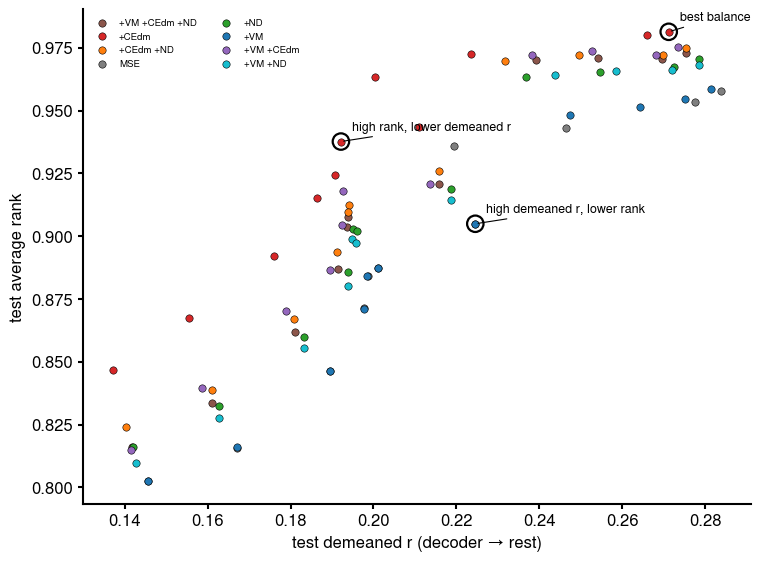

,decoder,combination,test demeaned r,test average rank,subject,subject demeaned r,subject rank
pick,,,,,,,
"high demeaned r, lower rank",cca_ridge pair wm,MSE,0.2246,0.9049,114823,0.2325,0.9185
"high rank, lower demeaned r",cca_ridge pair language,+CEdm,0.1921,0.9376,525541,0.1969,0.9348
best balance,cca_agg other7 emotion+gambling+language+motor...,+CEdm,0.2712,0.9813,506234,0.2712,0.9837


In [17]:
RX = np.load(A.OUT / "render" / "rest_examples_seed0.npz")
NP = 3
pts = H3[(H3.seed == 0) & (H3.target == "rest") & (H3.combo != "ridge") & (H3.source != "SC")].copy()
picks = {}
for j in range(NP):
    m = ((pts.model == str(RX[f"p{j}__model"])) & (pts.setting == str(RX[f"p{j}__setting"])) &
         (pts.source == str(RX[f"p{j}__source"])) & (pts.combo == str(RX[f"p{j}__combo"])))
    picks[str(RX[f"p{j}__name"])] = pts.index[m][0]
fig, ax = plt.subplots(figsize=(7.5, 5.5), layout="constrained")
for combo, g in pts.groupby("combo"):
    ax.scatter(g.demeaned_pearson, g.avg_rank, s=28, color=colors[combo], label=A.COMBO_LABEL[combo], edgecolor="black", lw=0.4)
for name, i in picks.items():
    ax.annotate(name, (pts.loc[i, "demeaned_pearson"], pts.loc[i, "avg_rank"]), xytext=(8, 8), textcoords="offset points",
                fontsize=9, arrowprops=dict(arrowstyle="-", lw=0.8))
    ax.scatter(pts.loc[i, "demeaned_pearson"], pts.loc[i, "avg_rank"], s=140, facecolor="none", edgecolor="black", lw=1.6)
ax.set_xlabel("test demeaned r (decoder → rest)"); ax.set_ylabel("test average rank"); ax.legend(fontsize=7, ncol=2)
plt.show()
display(pd.DataFrame([{"pick": str(RX[f"p{j}__name"]), "decoder": f"{RX[f'p{j}__model']} {RX[f'p{j}__setting']} {RX[f'p{j}__source']}",
                       "combination": A.COMBO_LABEL[str(RX[f"p{j}__combo"])],
                       "test demeaned r": float(RX[f"p{j}__test_dr"]), "test average rank": float(RX[f"p{j}__test_rank"]),
                       "subject": int(RX[f"p{j}__subject_id"]),
                       "subject demeaned r": float(RX[f"p{j}__subject_dr"][int(RX[f"p{j}__subject"])]),
                       "subject rank": float(RX[f"p{j}__subject_rank"][int(RX[f"p{j}__subject"])])} for j in range(NP)]).set_index("pick"))

findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Arial' not found.
findfont: Fon

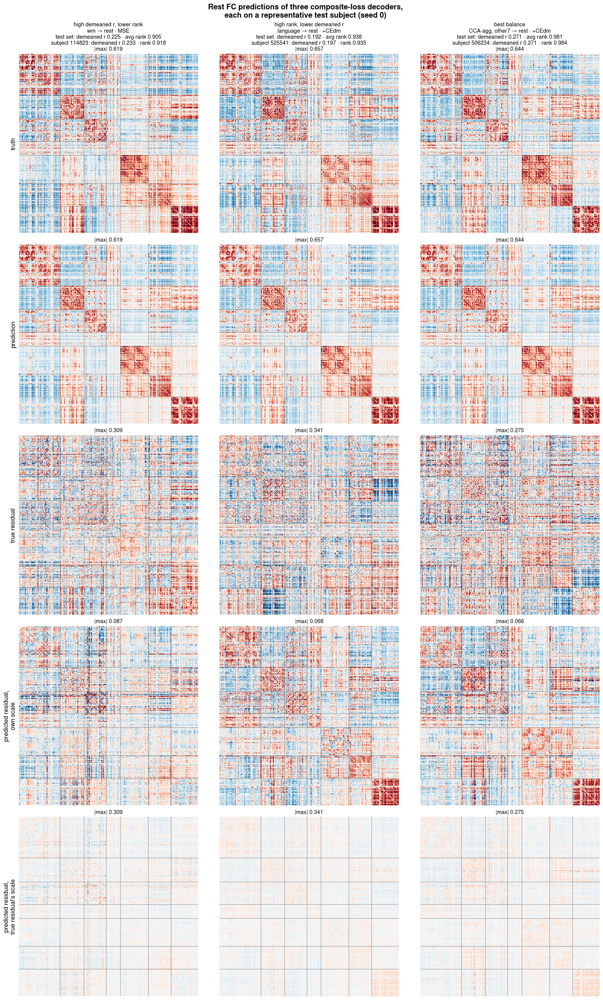

In [18]:
mu_e = RX["mu_rest"].astype(np.float64)
mu_rest = to_matrix(mu_e[None])[0]
iu = np.triu_indices(N_NODES, 1)
rows_ = ["truth", "prediction", "true residual", "predicted residual,\nown scale", "predicted residual,\ntrue residual's scale"]
fig, axes = plt.subplots(5, NP, figsize=(5.4 * NP, 5.3 * 5), layout="constrained")
for j in range(NP):
    s = int(RX[f"p{j}__subject"])
    T, Pm = to_matrix(RX[f"p{j}__true"][None].astype(np.float64))[0], to_matrix(RX[f"p{j}__pred"][None].astype(np.float64))[0]
    Dt, Dp = T - mu_rest, Pm - mu_rest
    lim_raw = np.percentile(np.abs(T[iu]), 99)
    lim_true, lim_own = np.percentile(np.abs(Dt[iu]), 99), np.percentile(np.abs(Dp[iu]), 99)
    src_ = str(RX[f"p{j}__source"]) if str(RX[f"p{j}__model"]) == "cca_ridge" else \
        f"{A.MODEL_LABEL[str(RX[f'p{j}__model'])]}, {RX[f'p{j}__setting']}"
    head = (f"{RX[f'p{j}__name']}\n{src_} → rest · {A.COMBO_LABEL[str(RX[f'p{j}__combo'])]}\n"
            f"test set: demeaned r {float(RX[f'p{j}__test_dr']):.3f} · avg rank {float(RX[f'p{j}__test_rank']):.3f}\n"
            f"subject {int(RX[f'p{j}__subject_id'])}: demeaned r {float(RX[f'p{j}__subject_dr'][s]):.3f} · "
            f"rank {float(RX[f'p{j}__subject_rank'][s]):.3f}\n")
    for k, (X, lim) in enumerate([(T, lim_raw), (Pm, lim_raw), (Dt, lim_true), (Dp, lim_own), (Dp, lim_true)]):
        ax = axes[k, j]
        ax.imshow(X[np.ix_(order, order)], cmap="RdBu_r", vmin=-lim, vmax=lim, interpolation="nearest")
        for b in bounds:
            ax.axhline(b, color="k", lw=0.3); ax.axvline(b, color="k", lw=0.3)
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        ax.set_title((head if k == 0 else "") + f"|max| {lim:.3f}", fontsize=10.5)
        if j == 0:
            ax.set_ylabel(rows_[k], fontsize=12)
fig.suptitle("Rest FC predictions of three composite-loss decoders,\neach on a representative test subject (seed 0)",
             fontweight="bold")
plt.show()

**Result: the composite terms trade demeaned r for identification. H3 is supported for Neighbour distance (alone and with Var-match) on every decoder group. Demeaned corr-eye gives the largest identification gains, but its accuracy cost exceeds the 0.005 margin except for SC → FC and FC → SC.**

Changes against the ridge decoder, mean over all 106 decoders × 5 seeds:
- **Demeaned corr-eye (CEdm):** average rank +0.041 ± 0.001, top-1 +0.060, demeaned r −0.011 ± 0.001 (5 / 5). It is the strongest identification term, at an accuracy cost twice the margin.
- **Neighbour distance (ND):** average rank +0.010 ± 0.001, top-1 +0.018, demeaned r −0.003 (5 / 5). This passes the rule.
- **Var-match:** inert (Δ ≈ 0).
- **Mixtures:** they interpolate between their components, ordered CEdm > CEdm + VM > three terms ≈ CEdm + ND > ND ≈ ND + VM.

The gains depend on the decoder group:
- **SC → FC:** CEdm raises average rank from 0.668 to 0.729 at −0.005 demeaned r. It is the only route that moves the SC → FC floor on identification.
- **FC → SC:** every term is inert (+0.001).
- **H2 decoders:** CEdm takes other 7 → held-out from average rank 0.916 to 0.950 and top-1 from 0.28 to 0.39.

The example figure shows what the terms do. All three predictions share the group-level structure (top row). Their residuals are about 3–6 times smaller than the true residual (bottom row, note the scales). Identity-aware terms reshape which part of the residual is reproduced; they do not add variance. These are the same trade-offs the composite-loss protocol (spec v2 E1) found for models trained end to end, here on a linear decoder from a fixed latent.

<a id="6-conclusions"></a>
## 6. Conclusions

1. **The CCA co-embedding is a better translation space than any PCA representation, for identification** (H1). Full-rank CCA beats the best PCA representation (R3, variance-adjusted block PCA, the best on every seed) by +0.027 average rank over the 72 pairs, at no cost in accuracy. The gain is largest for FC → SC (+0.058 average rank, +0.028 demeaned r) and absent for SC → FC.
2. **Representation matters within PCA as well:** R3 > R1 ≈ R2 > R0. Equal-variance pooling across conditions (D2) is the best linear transfer space. A basis built from the group-mean connectome (R0) reconstructs well but transfers worst. The Ledoit–Wolf conditional Gaussian never beats validation-tuned ridge.
3. **Truncation is a useful regulariser for identification.** CCA on 256 block-PCA codes identifies better than full-rank CCA (+0.018 average rank), which justifies E1 / E4's truncated latent when identification is the goal. Full rank is slightly more accurate.
4. **The latent pools views well** (H2). Averaging the encodings of the other views equals a decoder that weights them, beats the best single source by +0.03–0.04 average rank, and beats concatenated PCA codes by +0.02. SC adds nothing as an extra source, but it is best predicted from the pooled FC latent.
5. **Identity-aware decoder losses trade accuracy for identification** (H3). Neighbour distance passes the support rule; demeaned corr-eye gives four times the identification gain at about twice the allowed accuracy loss. The loss should follow the metric the application needs.
6. **Learned linear maps remain below the copy reference for FC → FC identification.** Copy reaches average rank 0.845 (single source) and 0.996 (other 7). Every learned map trails it. The subject-specific signal shared across conditions is small in variance (within-subject residual r ≈ 0.11) and largely outside what a linear map fit on 659 subjects transfers. Closing that gap is spec v4 E4's question.

<a id="7-appendix"></a>
## 7. Appendix: gates and reproducibility

- **G0** (E5.1): (a) the loaded edges equal spec v4 E2's per-seed cache; (b) R3 ridge at $k = 256$ with validation
  average-rank selection reproduces E4.0c's B1 rows; (c) full-rank CCA with E4.0c's selection and MAXVAR decoders
  reproduces E4.0c's B2 full-rank rows (max |Δ| < 1e-6); the code-space scorer equals explicit decoding.
- **G1** (E5.2): the MSE-only gradient decoders reproduce the ridge decoders (mean |Δ| < 0.002), and this job's ridge
  decoders reproduce E5.1's CCA rows.
- Code: `scripts/experiments/cca_analysis/` (`config.yml`, `e5_common.py`, `run_seed.py`, `run_composite.py`,
  `analyze.py`, `launch/`); results: `results/cache/experiments/cca_analysis/`; write-up:
  `scripts/experiments/cca_analysis/cca_analysis.md`.

In [19]:
display(pd.DataFrame(G0).T)
display(pd.DataFrame(G1).T)

,g0a_max_abs,g0b_max_abs,g0b_n,g0c_max_abs,g0c_n,fast_scorer_max_abs,pass
0,0.0,0.0,56,0.0,56,0.0,True
1,0.0,0.0,56,0.0,56,0.0,True
2,0.0,0.0,56,0.0,56,0.0,True
3,0.0,0.0,56,0.0,56,0.0,True
4,0.0,0.0,56,0.0,56,0.0,True


,pass,parts,mse_only_vs_ridge_dr,mse_only_vs_ridge_rank,ridge_vs_e51_dr_max
0,True,1,0.0,0.0001,0.0
1,True,2,0.0,0.0001,0.0
2,True,1,0.0,0.0002,0.0
3,True,1,0.0,0.0001,0.0
4,True,2,0.0,0.0001,0.0
